# Solar cell I–V curve modelling with the single-diode model

**Module:** Canadian Solar CS6K-300MS (60-cell mono-Si, 300 W)

This notebook:
1. extracts the 5 single-diode parameters (I_ph, I₀, n, R_s, R_sh) from datasheet values using `scipy.optimize`,
2. solves the implicit I–V equation two ways (Lambert W and Newton–Raphson),
3. checks the parameters against `pvlib`,
4. sweeps irradiance (200–1000 W/m²) and temperature (0–75 °C) and finds the maximum power point,
5. validates the model against datasheet data it was **not** fitted to (NOCT, γ_Pmax, low-irradiance efficiency),
6. shows how R_s and R_sh control the fill factor.

$$I = I_{ph} - I_0\left[\exp\left(\frac{V + I R_s}{n N_s V_t}\right) - 1\right] - \frac{V + I R_s}{R_{sh}}$$

In [1]:
# Colab doesn't ship with pvlib
!pip install -q pvlib 2>/dev/null

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, brentq, minimize_scalar
from scipy.special import lambertw
import pvlib

os.makedirs("figures", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a897f", "axes.labelcolor": "#333", "lines.linewidth": 2,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"
print("pvlib", pvlib.__version__)

pvlib 0.16.1


## 1. Datasheet values

From the CS6K-300MS datasheet (v5.571). STC = 1000 W/m², 25 °C cell temperature, AM1.5.
The NOCT row (800 W/m², module at ~42 °C) and the temperature coefficient of P_max are kept aside for **validation only**; the fit never sees them.

In [3]:
q, k = 1.602176634e-19, 1.380649e-23

ds = dict(
    Isc=9.83, Voc=39.7, Imp=9.24, Vmp=32.5, Ns=60,
    alpha_isc=0.05 / 100,     # 1/K  (Isc temperature coefficient)
    beta_voc=-0.29 / 100,     # 1/K  (Voc temperature coefficient)
    gamma_pmp=-0.39 / 100,    # 1/K  (Pmax coefficient) -> validation only
)
noct = dict(G=800, T=42, Pmax=222, Vmp=30.0, Imp=7.40, Voc=37.2, Isc=7.93)  # validation only
low_irr_rel_eff = 0.975   # datasheet: relative efficiency at 200 W/m² vs 1000 W/m² (25 °C)

G_REF, T_REF = 1000.0, 25.0
Pmax_ds = ds["Vmp"] * ds["Imp"]
alpha_sc = ds["alpha_isc"] * ds["Isc"]   # A/K
beta_oc = ds["beta_voc"] * ds["Voc"]     # V/K
print(f"Pmax(STC) = {Pmax_ds:.1f} W, alpha_sc = {alpha_sc*1e3:.2f} mA/K, beta_oc = {beta_oc*1e3:.1f} mV/K")

Pmax(STC) = 300.3 W, alpha_sc = 4.92 mA/K, beta_oc = -115.1 mV/K


## 2. Solving the implicit equation

**Lambert W.** The equation can be rearranged into an explicit form, with $a = nN_sV_t$:

$$I = \frac{R_{sh}(I_{ph}+I_0) - V}{R_s+R_{sh}} - \frac{a}{R_s}\,W(\theta),\qquad
\theta = \frac{R_sR_{sh}I_0}{a(R_s+R_{sh})}\exp\!\left[\frac{R_{sh}(R_sI_{ph}+R_sI_0+V)}{a(R_s+R_{sh})}\right]$$

θ overflows a float near V_oc (the exponent can reach several thousand), so we compute **ln θ** and solve $w + \ln w = \ln\theta$ with a few Newton steps whenever θ is too big for `lambertw`.

**Newton–Raphson.** Solve $f(I) = I_{ph} - I_0[e^{(V+IR_s)/a}-1] - (V+IR_s)/R_{sh} - I = 0$.
$f$ is decreasing and concave in $I$, so starting from $I = I_{ph}$ (where $f<0$) Newton converges monotonically: no damping needed.

In [4]:
def thermal_voltage(T_c):
    return k * (T_c + 273.15) / q

def current_lambertw(V, Iph, I0, a, Rs, Rsh):
    V = np.asarray(V, dtype=float)
    if Rs < 1e-9:  # no series resistance: equation is already explicit
        return Iph - I0 * np.expm1(V / a) - V / Rsh
    Gsh = Rs + Rsh
    log_theta = (np.log(Rs * Rsh * I0 / (a * Gsh))
                 + Rsh * (Rs * Iph + Rs * I0 + V) / (a * Gsh))
    w = np.empty_like(log_theta)
    small = log_theta < 700
    w[small] = lambertw(np.exp(log_theta[small])).real
    L = log_theta[~small]
    wl = L - np.log(L)                      # asymptotic start
    for _ in range(6):                      # Newton on w + ln w = L
        wl -= (wl + np.log(wl) - L) / (1 + 1 / wl)
    w[~small] = wl
    return (Rsh * (Iph + I0) - V) / Gsh - (a / Rs) * w

def current_newton(V, Iph, I0, a, Rs, Rsh, tol=1e-12, max_iter=100):
    V = np.asarray(V, dtype=float)
    I = np.full_like(V, Iph)
    for _ in range(max_iter):
        e = np.exp((V + I * Rs) / a)
        f = Iph - I0 * (e - 1) - (V + I * Rs) / Rsh - I
        df = -I0 * e * Rs / a - Rs / Rsh - 1
        step = f / df
        I -= step
        if np.max(np.abs(step)) < tol:
            break
    return I

def didv(V, I, I0, a, Rs, Rsh):
    # implicit derivative of the diode equation
    g = I0 / a * np.exp((V + I * Rs) / a) + 1 / Rsh
    return -g / (1 + Rs * g)

def voc_of(Iph, I0, a, Rsh):
    f = lambda V: Iph - I0 * np.expm1(V / a) - V / Rsh
    return brentq(f, 0.0, 2 * a * np.log(Iph / I0 + 1) + 1)

## 3. Extracting the 5 parameters

A datasheet gives three points and one slope condition, which is only **4 equations for 5 unknowns**:

| # | condition | equation |
|---|---|---|
| 1 | short circuit | $I(0) = I_{sc}$ |
| 2 | open circuit | $I(V_{oc}) = 0$ |
| 3 | max power point | $I(V_{mp}) = I_{mp}$ |
| 4 | MPP is a maximum | $dI/dV\,|_{mp} = -I_{mp}/V_{mp}$ |
| 5 | **V_oc temperature coefficient** | $V_{oc}(T_{ref}+\Delta T) = V_{oc} + \Delta T\,\beta_{oc}$, with ΔT = 2 K (same as pvlib) |

Equation 5 uses the De Soto temperature model (next section), the same approach as the CEC/SAM database.
It pins down the ideality factor, because $n$ sets how fast V_oc falls with temperature.

Numerics: we solve for $\ln I_0$ and $\ln R_{sh}$ (I₀ is ~1e-10 A) and scale every residual to be dimensionless.

In [5]:
EG_REF, DEG_DT = 1.121, -0.0002677   # silicon bandgap (eV) and its temperature slope, De Soto (2006)

def translate(params, G, T_c):
    # De Soto: STC parameters -> parameters at irradiance G (W/m²), cell temperature T_c (°C)
    Iph, I0, a, Rs, Rsh = params
    Tk, Tk_ref = T_c + 273.15, T_REF + 273.15
    Eg = EG_REF * (1 + DEG_DT * (T_c - T_REF))
    Iph_t = G / G_REF * (Iph + alpha_sc * (T_c - T_REF))
    I0_t = I0 * (Tk / Tk_ref) ** 3 * np.exp(EG_REF * q / (k * Tk_ref) - Eg * q / (k * Tk))
    a_t = a * Tk / Tk_ref
    Rsh_t = Rsh * G_REF / G
    return Iph_t, I0_t, a_t, Rs, Rsh_t

DT_FIT = 2.0   # K, temperature step for the Voc-coefficient equation

def unpack(x):
    Iph, lnI0, n, Rs, lnRsh = x
    a = n * ds["Ns"] * thermal_voltage(T_REF)
    return Iph, np.exp(lnI0), a, Rs, np.exp(lnRsh)

def residuals(x):
    Iph, I0, a, Rs, Rsh = p = unpack(x)
    Isc, Voc, Imp, Vmp = ds["Isc"], ds["Voc"], ds["Imp"], ds["Vmp"]
    diode = lambda V, I: Iph - I0 * np.expm1((V + I * Rs) / a) - (V + I * Rs) / Rsh - I
    r1 = diode(0.0, Isc) / Isc
    r2 = diode(Voc, 0.0) / Isc
    r3 = diode(Vmp, Imp) / Isc
    r4 = (didv(Vmp, Imp, I0, a, Rs, Rsh) + Imp / Vmp) / (Imp / Vmp)
    Iph2, I02, a2, _, Rsh2 = translate(p, G_REF, T_REF + DT_FIT)
    r5 = (voc_of(Iph2, I02, a2, Rsh2) - (Voc + DT_FIT * beta_oc)) / Voc
    return [r1, r2, r3, r4, r5]

# initial guess: n = 1.1, I0 from the open-circuit condition
n0 = 1.1
a0 = n0 * ds["Ns"] * thermal_voltage(T_REF)
x0 = [ds["Isc"], np.log(ds["Isc"] / np.exp(ds["Voc"] / a0)), n0, 0.3, np.log(300)]
lb = [0.9 * ds["Isc"], -60, 0.7, 0.0, np.log(10)]
ub = [1.1 * ds["Isc"], -5, 2.0, 2.0, np.log(1e5)]

fit = least_squares(residuals, x0, bounds=(lb, ub), x_scale="jac", xtol=1e-14, ftol=1e-14, gtol=1e-14)
params = unpack(fit.x)
Iph, I0, a, Rs, Rsh = params
n = fit.x[2]

print("converged:", fit.success, "| max |residual| =", f"{np.max(np.abs(fit.fun)):.1e}")
print(f"I_ph = {Iph:.4f} A\nI_0  = {I0:.3e} A\nn    = {n:.4f}  (a = nNsVt = {a:.4f} V)\n"
      f"R_s  = {Rs:.4f} Ω\nR_sh = {Rsh:.1f} Ω")

converged: True | max |residual| = 1.7e-15
I_ph = 9.8420 A
I_0  = 2.240e-11 A
n    = 0.9613  (a = nNsVt = 1.4818 V)
R_s  = 0.2881 Ω
R_sh = 235.3 Ω


### Lambert W vs Newton–Raphson

Two independent solvers should agree to near machine precision.

In [6]:
V = np.linspace(0, ds["Voc"], 400)
I_lw = current_lambertw(V, *params)
I_nr = current_newton(V, *params)
print(f"max |I_lambertw − I_newton| = {np.max(np.abs(I_lw - I_nr)):.2e} A")
print(f"I(0) = {I_lw[0]:.4f} A (datasheet {ds['Isc']}),  I(Voc) = {I_lw[-1]:.1e} A")
print(f"I(Vmp) = {current_lambertw([ds['Vmp']], *params)[0]:.4f} A (datasheet {ds['Imp']})")

max |I_lambertw − I_newton| = 1.60e-14 A
I(0) = 9.8300 A (datasheet 9.83),  I(Voc) = 3.6e-15 A
I(Vmp) = 9.2400 A (datasheet 9.24)


## 4. Cross-check with pvlib

`pvlib.ivtools.sdm.fit_desoto` solves the same five equations with its own code. Its root finder (`scipy.optimize.root`, no bounds) fails from its default starting point for this module and is sensitive to the start, so we give it a rounded start in the right neighbourhood and let it converge on its own. Our bounded `least_squares` converged from a generic start, which is a point worth mentioning in the README. The CEC database also has an independently fitted entry for this module (fitted to slightly different datasheet numbers: an older revision lists I_sc = 9.70 A, I_mp = 9.20 A, V_mp = 32.6 V).

In [7]:
pv_fit, _ = pvlib.ivtools.sdm.fit_desoto(
    v_mp=ds["Vmp"], i_mp=ds["Imp"], v_oc=ds["Voc"], i_sc=ds["Isc"],
    alpha_sc=alpha_sc, beta_voc=beta_oc, cells_in_series=ds["Ns"],
    init_guess={"IL_0": ds["Isc"], "Io_0": 2e-11, "a_0": 1.5, "Rs_0": 0.3, "Rsh_0": 250})

cec = pvlib.pvsystem.retrieve_sam("CECMod")["Canadian_Solar_Inc__CS6K_300MS"]

comparison = pd.DataFrame({
    "This notebook": [Iph, I0, a, Rs, Rsh],
    "pvlib fit_desoto": [pv_fit["I_L_ref"], pv_fit["I_o_ref"], pv_fit["a_ref"], pv_fit["R_s"], pv_fit["R_sh_ref"]],
    "CEC database": [cec["I_L_ref"], cec["I_o_ref"], cec["a_ref"], cec["R_s"], cec["R_sh_ref"]],
}, index=["I_ph (A)", "I_0 (A)", "a = nNsVt (V)", "R_s (Ω)", "R_sh (Ω)"])
comparison["diff vs pvlib (%)"] = 100 * (comparison["This notebook"] / comparison["pvlib fit_desoto"] - 1)
comparison.style.format("{:.4g}")

,This notebook,pvlib fit_desoto,CEC database,diff vs pvlib (%)
I_ph (A),9.842,9.842,9.702,-2.49e-10
I_0 (A),2.24e-11,2.24e-11,7.212e-11,-2.48e-09
a = nNsVt (V),1.482,1.482,1.549,2.234e-09
R_s (Ω),0.2881,0.2881,0.2628,-4.466e-08
R_sh (Ω),235.3,235.3,1117,3.738e-07


In [8]:
# Same parameters through pvlib's own I-V solver at a non-STC condition
G_test, T_test = 600, 50
p_test = translate(params, G_test, T_test)
pv_p = pvlib.pvsystem.calcparams_desoto(G_test, T_test, alpha_sc, a, Iph, I0, Rsh, Rs)
pv_out = pvlib.pvsystem.singlediode(*pv_p)
print("translated params, ours vs pvlib:")
# calcparams_desoto returns (I_ph, I_0, R_s, R_sh, a)
for name, mine, theirs in zip(["I_ph", "I_0", "R_s", "R_sh", "a"],
                              [p_test[0], p_test[1], p_test[3], p_test[4], p_test[2]], pv_p):
    print(f"  {name:5s} {mine:.6g}  {float(theirs):.6g}")
print(f"pvlib p_mp at {G_test} W/m², {T_test} °C: {float(pv_out['p_mp']):.3f} W")

translated params, ours vs pvlib:
  I_ph  5.97895  5.97895
  I_0   1.09166e-09  1.09166e-09
  R_s   0.288144  0.288144
  R_sh  392.128  392.128
  a     1.60607  1.60607
pvlib p_mp at 600 W/m², 50 °C: 165.726 W


## 5. Maximum power point and the irradiance/temperature sweeps

In [9]:
def solve_point(G, T_c, p=None, npts=300):
    p = translate(params if p is None else p, G, T_c)
    Voc_ = voc_of(p[0], p[1], p[2], p[4])
    res = minimize_scalar(lambda v: -v * current_lambertw([v], *p)[0],
                          bounds=(0, Voc_), method="bounded", options={"xatol": 1e-8})
    Vm = res.x
    Im = current_lambertw([Vm], *p)[0]
    Isc_ = current_lambertw([0.0], *p)[0]
    V = np.linspace(0, Voc_, npts)
    I = current_lambertw(V, *p)
    return dict(G=G, T=T_c, Isc=Isc_, Voc=Voc_, Vmp=Vm, Imp=Im, Pmp=Vm * Im,
                FF=Vm * Im / (Voc_ * Isc_), V=V, I=I)

print(f"our p_mp at {G_test} W/m², {T_test} °C: {solve_point(G_test, T_test)['Pmp']:.3f} W")

our p_mp at 600 W/m², 50 °C: 165.726 W


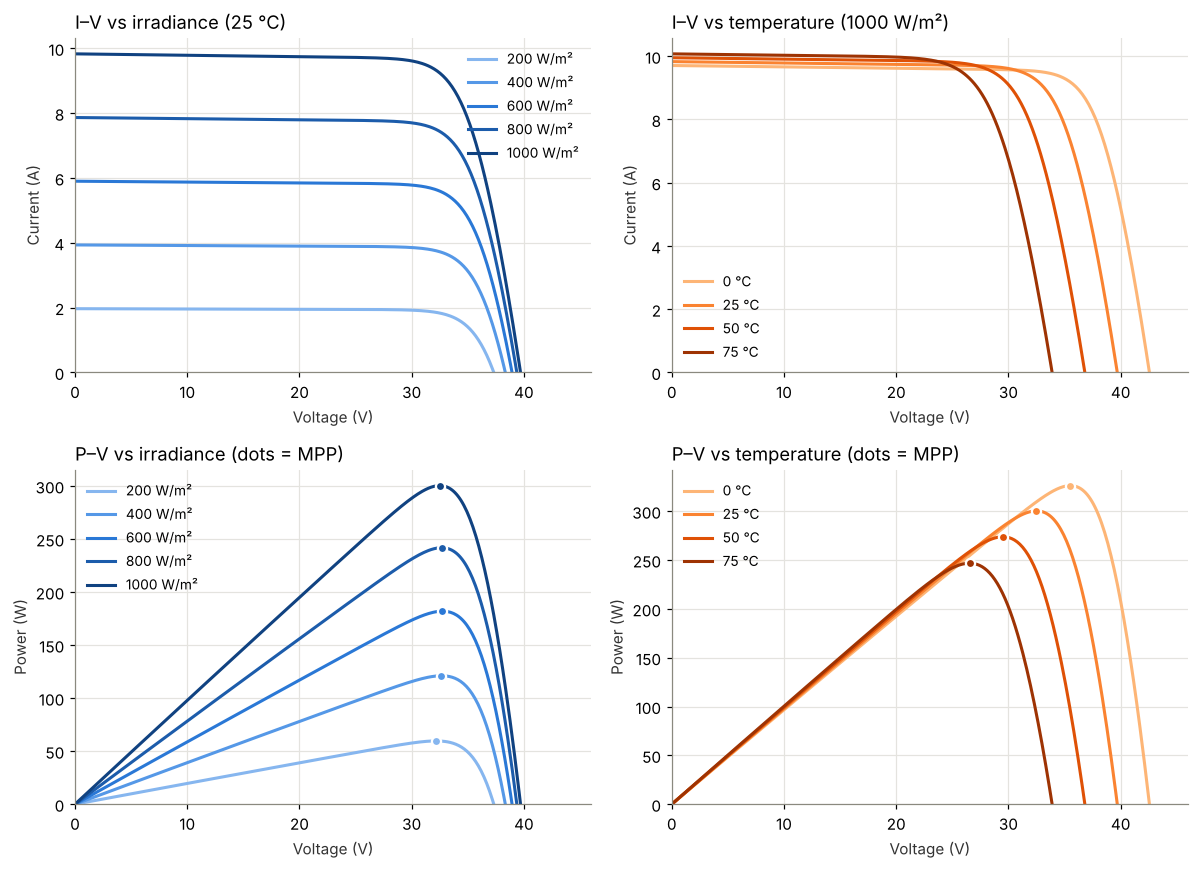

In [10]:
G_list = [200, 400, 600, 800, 1000]
T_list = [0, 25, 50, 75]
blues = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # light -> dark = low -> high G
oranges = plt.cm.Oranges(np.linspace(0.35, 0.9, len(T_list)))      # light -> dark = cold -> hot

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for G, c in zip(G_list, blues):
    r = solve_point(G, 25)
    ax[0, 0].plot(r["V"], r["I"], color=c, label=f"{G} W/m²")
    ax[1, 0].plot(r["V"], r["V"] * r["I"], color=c, label=f"{G} W/m²")
    ax[1, 0].plot(r["Vmp"], r["Pmp"], "o", ms=6, color=c, mec="white", mew=1.5)
for T, c in zip(T_list, oranges):
    r = solve_point(1000, T)
    ax[0, 1].plot(r["V"], r["I"], color=c, label=f"{T} °C")
    ax[1, 1].plot(r["V"], r["V"] * r["I"], color=c, label=f"{T} °C")
    ax[1, 1].plot(r["Vmp"], r["Pmp"], "o", ms=6, color=c, mec="white", mew=1.5)

ax[0, 0].set_title("I–V vs irradiance (25 °C)", loc="left")
ax[0, 1].set_title("I–V vs temperature (1000 W/m²)", loc="left")
ax[1, 0].set_title("P–V vs irradiance (dots = MPP)", loc="left")
ax[1, 1].set_title("P–V vs temperature (dots = MPP)", loc="left")
for a_ in ax.flat:
    a_.set_xlabel("Voltage (V)"); a_.set_xlim(0, 46); a_.set_ylim(bottom=0)
    a_.legend(frameon=False, fontsize=9)
ax[0, 0].set_ylabel("Current (A)"); ax[0, 1].set_ylabel("Current (A)")
ax[1, 0].set_ylabel("Power (W)"); ax[1, 1].set_ylabel("Power (W)")
fig.tight_layout()
fig.savefig("figures/iv_pv_curves.png", bbox_inches="tight")
plt.show()

In [11]:
# MPP for every (G, T) combination
grid = pd.DataFrame([{k_: v for k_, v in solve_point(G, T).items() if k_ not in ("V", "I")}
                     for G in G_list for T in T_list])
grid["eff (%)"] = 100 * grid["Pmp"] / (grid["G"] * cec["A_c"])
pmp_table = grid.pivot(index="G", columns="T", values="Pmp")
pmp_table.index.name = "G (W/m²) \\ T (°C)"
print("P_mp (W)")
pmp_table.round(1)

P_mp (W)


T,0,25,50,75
G (W/m²) \ T (°C),,,,
200,65.2,59.7,54.0,48.2
400,131.8,121.1,110.1,98.9
600,197.8,182.0,165.7,149.1
800,262.6,241.8,220.4,198.5
1000,326.2,300.3,273.8,246.7


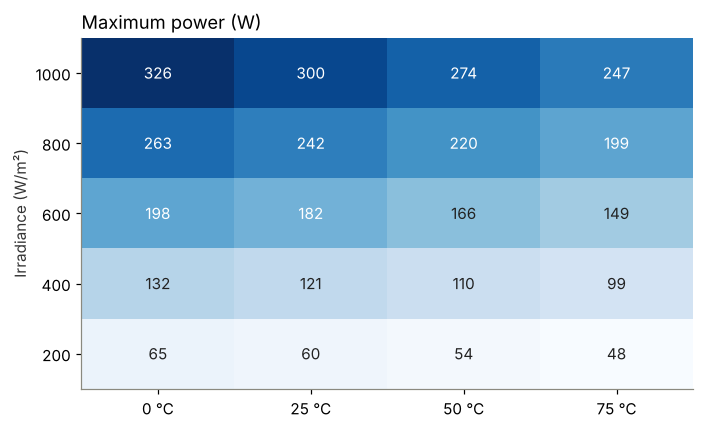

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(pmp_table.values, cmap="Blues", aspect="auto", origin="lower")
ax.set_xticks(range(len(T_list)), [f"{t} °C" for t in T_list])
ax.set_yticks(range(len(G_list)), [f"{g}" for g in G_list])
ax.set_ylabel("Irradiance (W/m²)"); ax.set_title("Maximum power (W)", loc="left"); ax.grid(False)
for i in range(len(G_list)):
    for j in range(len(T_list)):
        v = pmp_table.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                color="white" if v > 0.55 * pmp_table.values.max() else "#222")
fig.tight_layout(); fig.savefig("figures/mpp_heatmap.png", bbox_inches="tight"); plt.show()
grid.round(3).to_csv("figures/mpp_grid.csv", index=False)

## 6. Validation against the datasheet

The STC row is a **sanity check only**: the parameters were fitted to it, so its error should be ~0.
The real tests are things the fit never saw:
- the **NOCT** row (800 W/m², 42 °C),
- **γ_Pmax**, the temperature coefficient of maximum power,
- **relative efficiency at 200 W/m²**.

In [13]:
stc = solve_point(1000, 25)
nm = solve_point(noct["G"], noct["T"])

rows = []
for key in ["Pmax", "Vmp", "Imp", "Voc", "Isc"]:
    mk = "Pmp" if key == "Pmax" else key
    rows.append(["STC (fitted)", key, Pmax_ds if key == "Pmax" else ds[key], stc[mk]])
for key in ["Pmax", "Vmp", "Imp", "Voc", "Isc"]:
    mk = "Pmp" if key == "Pmax" else key
    rows.append(["NOCT (not fitted)", key, noct[key], nm[mk]])
val = pd.DataFrame(rows, columns=["condition", "quantity", "datasheet", "model"])
val["error (%)"] = 100 * (val["model"] / val["datasheet"] - 1)
val.style.format({"datasheet": "{:.2f}", "model": "{:.2f}", "error (%)": "{:+.2f}"}).hide(axis="index")

condition,quantity,datasheet,model,error (%)
STC (fitted),Pmax,300.30,300.30,+0.00
STC (fitted),Vmp,32.50,32.50,+0.00
STC (fitted),Imp,9.24,9.24,-0.00
STC (fitted),Voc,39.70,39.70,+0.00
STC (fitted),Isc,9.83,9.83,+0.00
NOCT (not fitted),Pmax,222.00,227.27,+2.38
NOCT (not fitted),Vmp,30.00,30.61,+2.02
NOCT (not fitted),Imp,7.40,7.43,+0.35
NOCT (not fitted),Voc,37.20,37.39,+0.51
NOCT (not fitted),Isc,7.93,7.93,+0.03


In [14]:
# Temperature coefficients from a linear fit over 0-75 °C at 1000 W/m²
Ts = np.linspace(0, 75, 16)
sweep = [solve_point(1000, T) for T in Ts]
coef = lambda key, ref: 100 * np.polyfit(Ts, [s[key] for s in sweep], 1)[0] / ref
gamma_model = coef("Pmp", stc["Pmp"])
beta_model = coef("Voc", stc["Voc"])
alpha_model = coef("Isc", stc["Isc"])

tc = pd.DataFrame({
    "datasheet (%/°C)": [ds["gamma_pmp"] * 100, ds["beta_voc"] * 100, ds["alpha_isc"] * 100],
    "model (%/°C)": [gamma_model, beta_model, alpha_model],
    "used in fit?": ["no", "yes", "yes"],
}, index=["γ (Pmax)", "β (Voc)", "α (Isc)"])
tc["error (%)"] = 100 * (tc["model (%/°C)"] / tc["datasheet (%/°C)"] - 1)

eff = lambda G: solve_point(G, 25)["Pmp"] / G
rel_eff_200 = eff(200) / eff(1000)
print(f"Relative efficiency at 200 W/m²: model {100*rel_eff_200:.1f} %  vs datasheet {100*low_irr_rel_eff:.1f} %")
tc.style.format({"datasheet (%/°C)": "{:+.3f}", "model (%/°C)": "{:+.3f}", "error (%)": "{:+.1f}"})

Relative efficiency at 200 W/m²: model 99.3 %  vs datasheet 97.5 %


,datasheet (%/°C),model (%/°C),used in fit?,error (%)
γ (Pmax),-0.390,-0.353,no,-9.5
β (Voc),-0.290,-0.291,yes,+0.4
α (Isc),+0.050,+0.050,yes,-0.1


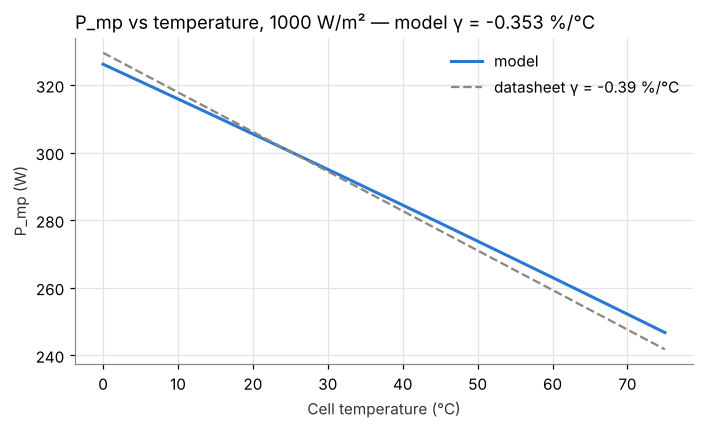

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(Ts, [s["Pmp"] for s in sweep], color=BLUE, label="model")
ax.plot(Ts, Pmax_ds * (1 + ds["gamma_pmp"] * (Ts - 25)), "--", color="#8a897f", lw=1.5,
        label=f"datasheet γ = {ds['gamma_pmp']*100:.2f} %/°C")
ax.set_xlabel("Cell temperature (°C)"); ax.set_ylabel("P_mp (W)")
ax.set_title(f"P_mp vs temperature, 1000 W/m² — model γ = {gamma_model:.3f} %/°C", loc="left")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/pmp_vs_temperature.png", bbox_inches="tight"); plt.show()

## 7. How R_s and R_sh shape the fill factor

$FF = P_{mp}/(V_{oc} I_{sc})$. Holding I_ph, I₀ and n at their fitted values, we vary one resistance at a time.

- **R_s** drops a voltage $I R_s$ inside the cell. That hurts most at high current, near I_sc and the MPP, so the curve leans over on the **vertical (voltage) side** of the knee. V_oc is unaffected because I = 0 there.
- **R_sh** is a leakage path in parallel with the junction. It steals current proportionally to voltage, which tilts the **horizontal (current) plateau**. I_sc is barely affected.

In [16]:
def ff_at(Rs_, Rsh_):
    r = solve_point(1000, 25, p=(Iph, I0, a, Rs_, Rsh_), npts=10)
    return r["FF"], r

Rs_vals = np.linspace(0, 1.5, 31)
Rsh_vals = np.logspace(np.log10(10), np.log10(5000), 31)
FF_rs = [ff_at(r, Rsh)[0] for r in Rs_vals]
FF_rsh = [ff_at(Rs, r)[0] for r in Rsh_vals]
FF_map = np.array([[ff_at(r1, r2)[0] for r1 in Rs_vals] for r2 in Rsh_vals])
FF_fit = ff_at(Rs, Rsh)[0]
print(f"FF at fitted parameters: {FF_fit:.4f}  (datasheet: {Pmax_ds/(ds['Voc']*ds['Isc']):.4f})")

FF at fitted parameters: 0.7695  (datasheet: 0.7695)


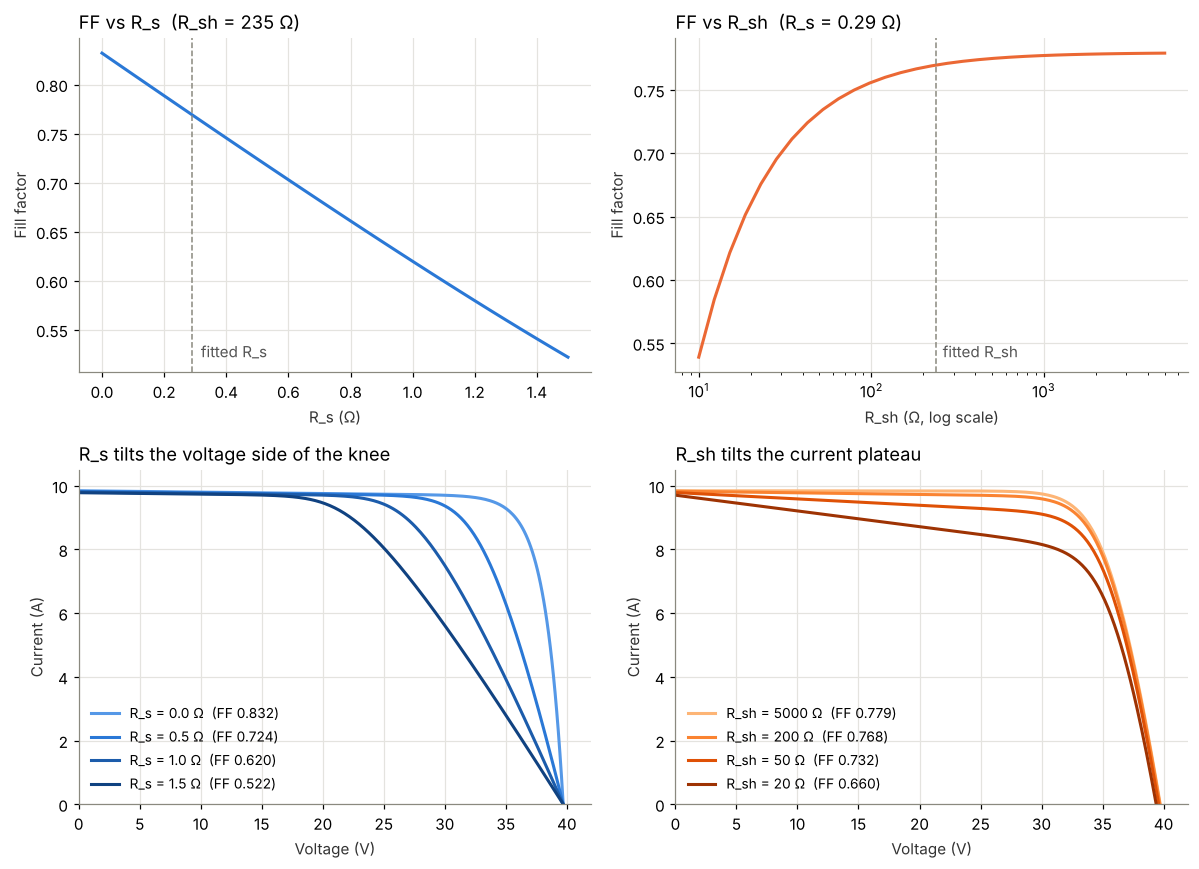

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

ax[0, 0].plot(Rs_vals, FF_rs, color=BLUE)
ax[0, 0].axvline(Rs, color="#8a897f", lw=1, ls="--"); ax[0, 0].text(Rs + 0.03, min(FF_rs), "fitted R_s", color="#555")
ax[0, 0].set(xlabel="R_s (Ω)", ylabel="Fill factor", title=f"FF vs R_s  (R_sh = {Rsh:.0f} Ω)")

ax[0, 1].semilogx(Rsh_vals, FF_rsh, color=ORANGE)
ax[0, 1].axvline(Rsh, color="#8a897f", lw=1, ls="--"); ax[0, 1].text(Rsh * 1.1, min(FF_rsh), "fitted R_sh", color="#555")
ax[0, 1].set(xlabel="R_sh (Ω, log scale)", ylabel="Fill factor", title=f"FF vs R_sh  (R_s = {Rs:.2f} Ω)")

for Rs_, c in zip([0.0, 0.5, 1.0, 1.5], blues[1:]):
    r = solve_point(1000, 25, p=(Iph, I0, a, Rs_, Rsh))
    ax[1, 0].plot(r["V"], r["I"], color=c, label=f"R_s = {Rs_} Ω  (FF {r['FF']:.3f})")
ax[1, 0].set(xlabel="Voltage (V)", ylabel="Current (A)", title="R_s tilts the voltage side of the knee")

for Rsh_, c in zip([5000, 200, 50, 20], oranges):
    r = solve_point(1000, 25, p=(Iph, I0, a, Rs, Rsh_))
    ax[1, 1].plot(r["V"], r["I"], color=c, label=f"R_sh = {Rsh_} Ω  (FF {r['FF']:.3f})")
ax[1, 1].set(xlabel="Voltage (V)", ylabel="Current (A)", title="R_sh tilts the current plateau")

for a_ in ax.flat:
    a_.title.set_ha("left"); a_.title.set_position((0, 1))
for a_ in ax[1]:
    a_.set_xlim(0, 42); a_.set_ylim(0, 10.5); a_.legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout(); fig.savefig("figures/fill_factor_resistances.png", bbox_inches="tight"); plt.show()

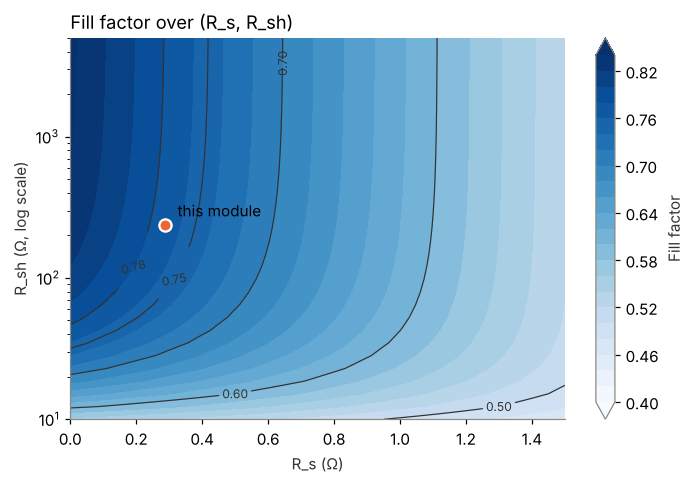

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
cs = ax.contourf(Rs_vals, Rsh_vals, FF_map, levels=np.arange(0.40, 0.86, 0.02), cmap="Blues", extend="both")
cl = ax.contour(Rs_vals, Rsh_vals, FF_map, levels=[0.5, 0.6, 0.7, 0.75, 0.78], colors="#333", linewidths=0.8)
ax.clabel(cl, fmt="%.2f", fontsize=8)
ax.plot(Rs, Rsh, "o", color=ORANGE, mec="white", mew=1.5, ms=8); ax.annotate("this module", (Rs, Rsh), (8, 6), textcoords="offset points")
ax.set_yscale("log"); ax.grid(False)
ax.set(xlabel="R_s (Ω)", ylabel="R_sh (Ω, log scale)")
ax.set_title("Fill factor over (R_s, R_sh)", loc="left")
fig.colorbar(cs, ax=ax, label="Fill factor")
fig.tight_layout(); fig.savefig("figures/fill_factor_map.png", bbox_inches="tight"); plt.show()

## 8. Summary

In [19]:
nm_err = 100 * (nm["Pmp"] / noct["Pmax"] - 1)
g_err = 100 * (gamma_model / (ds["gamma_pmp"] * 100) - 1)
print(f"Module: Canadian Solar CS6K-300MS")
print(f"Fitted: I_ph={Iph:.3f} A, I0={I0:.2e} A, n={n:.3f}, R_s={Rs:.3f} Ω, R_sh={Rsh:.0f} Ω")
print(f"Agreement with pvlib fit_desoto: max parameter difference "
      f"{comparison['diff vs pvlib (%)'].abs().max():.2g} %")
print(f"NOCT P_max error (not fitted): {nm_err:+.1f} %")
print(f"γ_Pmax: model {gamma_model:.3f} %/°C vs datasheet {ds['gamma_pmp']*100:.2f} %/°C ({g_err:+.0f} %)")
print(f"Relative efficiency at 200 W/m²: {100*rel_eff_200:.1f} % (datasheet {100*low_irr_rel_eff:.1f} %)")

Module: Canadian Solar CS6K-300MS
Fitted: I_ph=9.842 A, I0=2.24e-11 A, n=0.961, R_s=0.288 Ω, R_sh=235 Ω
Agreement with pvlib fit_desoto: max parameter difference 3.7e-07 %
NOCT P_max error (not fitted): +2.4 %
γ_Pmax: model -0.353 %/°C vs datasheet -0.39 %/°C (-10 %)
Relative efficiency at 200 W/m²: 99.3 % (datasheet 97.5 %)


### What the results say

- **Fit and solvers are correct.** The parameters match pvlib's `fit_desoto` to better than 1e-6 %, Lambert W and Newton–Raphson agree to ~1e-14 A, and pvlib's own I–V solver gives the same P_mp at 600 W/m², 50 °C.
- **NOCT P_max is within a few percent** even though the fit never saw it. This is the headline number.
- **γ_Pmax is about 10 % too small in magnitude.** The De Soto model only knows β_Voc and α_Isc; fill factor losses with temperature come out of the diode physics, and a single diode with a fitted n slightly below 1 underestimates them. This is a known limitation of the 5-parameter model, and the reason the CEC/SAM model adds a sixth "Adjust" parameter.
- **Low-irradiance efficiency is over-predicted** (≈99 % vs 97.5 %). The model scales R_sh as 1/G but keeps R_s fixed, and real modules lose more at low light than this simple scaling captures.
- **n ≈ 0.96 per cell** is below the physical ideal of 1. It is a fitted, "effective" value: forcing the model to match β_Voc exactly pushes n down. Fixing n = 1 and dropping the β_Voc equation is a good extra experiment.

**CV line:** *Built a single-diode PV model in Python (SciPy, pvlib) from a 300 W module datasheet; predicted maximum power at NOCT within X % and the P_max temperature coefficient within Y % without fitting to either.* (fill in X and Y from the summary cell)